# Credit Score Classification — Eksplorasi Data & Modelling



Outline:
1. Load & lihat sekilas data
2. Distribusi target
3. Investigasi kualitas data (data ini cukup berantakan)
4. Cleaning + feature engineering
5. Handling missing value & encoding
6. EDA singkat
7. Training beberapa model + perbandingan
8. Evaluasi model terbaik

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

df = pd.read_csv("data_A.csv", index_col=0)
print(df.shape)
df.head()

(25000, 28)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0xa658,CUS_0x936d,March,Alistair Barrs,8466,703-48-3482,_______,100433.58,8074.465000,1,5,10,2,"Student Loan, and Debt Consolidation Loan",13,4,12.59,3.0,Good,1023.93,33.471395,20 Years and 5 Months,No,100.163466,758.0704866746678,Low_spent_Medium_value_payments,229.21254743638283,Standard
1,0x6739,CUS_0x9a29,August,Phila,25,339-28-0072,Developer,33119.82,3024.985000,10,5,32,5,"Home Equity Loan, Mortgage Loan, Home Equity L...",50,18,15.79,10.0,Bad,2545.0,33.810567,14 Years and 8 Months,Yes,111.422702,NaN,Low_spent_Small_value_payments,370.6074980582689,Poor
2,0xdcf5,CUS_0x12a9,April,Driverb,44,583-20-9758,_______,44822.21,3555.184167,1,4,2,4,"Credit-Builder Loan, Debt Consolidation Loan, ...",14,8,4.03,0.0,Good,730.64,31.145739,23 Years and 10 Months,NM,135.044286,256.4742969677053,Low_spent_Medium_value_payments,243.99983412342044,Standard
3,0x14453,CUS_0x3bad,June,Prasadc,29,510-25-2095,Musician,142081.48,11771.123333,6,6,15,3_,"Personal Loan, Not Specified, and Mortgage Loan",29,20,8.21,4.0,Standard,932.32,28.409526,27 Years and 0 Months,No,180.616478,423.96126196668365,Low_spent_Small_value_payments,862.534593039876,Standard
4,0x1198e,CUS_0xa3e1,January,Poornimai,45,943-92-4350,Scientist,19267.27_,1374.605833,10,8,25,6,"Home Equity Loan, Auto Loan, Payday Loan, Not ...",33,NaN,19.7,6.0,Bad,3777.55,28.373426,10 Years and 3 Months,Yes,78.954825,133.56850235207634,Low_spent_Small_value_payments,214.93725572483646,Poor


## 1. Lihat sekilas

Cek tipe data tiap kolom. Beberapa kolom yang harusnya angka malah `object` — pertanda ada karakter aneh di dalamnya.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25000 entries, 0 to 24999
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        25000 non-null  object 
 1   Customer_ID               25000 non-null  object 
 2   Month                     25000 non-null  object 
 3   Name                      22440 non-null  object 
 4   Age                       25000 non-null  object 
 5   SSN                       25000 non-null  object 
 6   Occupation                25000 non-null  object 
 7   Annual_Income             25000 non-null  object 
 8   Monthly_Inhand_Salary     21417 non-null  float64
 9   Num_Bank_Accounts         25000 non-null  int64  
 10  Num_Credit_Card           25000 non-null  int64  
 11  Interest_Rate             25000 non-null  int64  
 12  Num_of_Loan               25000 non-null  object 
 13  Type_of_Loan              22172 non-null  object 
 14  Delay_from_

## 2. Distribusi target

Target tidak seimbang: `Standard` mendominasi. Ini penting nanti — akurasi saja bisa menyesatkan, jadi saya akan pakai **F1-macro** sebagai metrik utama.

Credit_Score
Standard    13330
Poor         7302
Good         4368
Name: count, dtype: int64


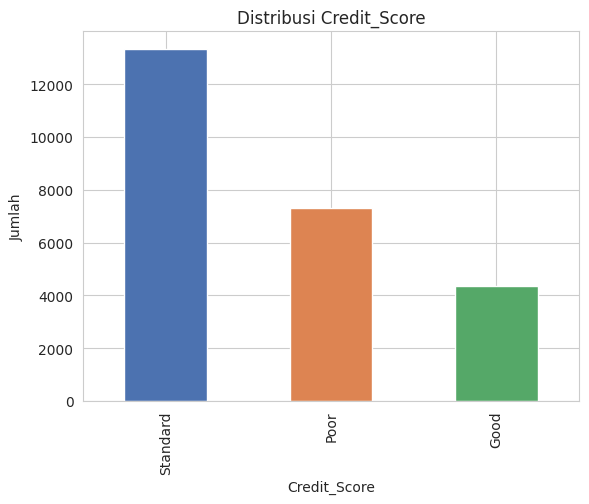

In [3]:
print(df["Credit_Score"].value_counts())
ax = df["Credit_Score"].value_counts().plot(kind="bar", color=["#4c72b0","#dd8452","#55a868"])
ax.set_title("Distribusi Credit_Score"); ax.set_ylabel("Jumlah"); plt.show()

## 3. Investigasi kualitas data

Beberapa masalah yang langsung kelihatan waktu scroll data:
- Angka yang kebawa underscore, mis. `39_`, `19267.27_` (kesalahan input/parsing).
- Token placeholder/sampah: `_______` (Occupation), `_` (Credit_Mix), `!@9#%8` (Payment_Behaviour), SSN ngawur.
- Outlier ekstrem yang mustahil: umur ribuan tahun, jumlah kartu kredit ratusan.
- `Credit_History_Age` dalam bentuk teks "X Years and Y Months".
- `Type_of_Loan` multi-nilai dipisah koma.

Mari dibuktikan satu-satu.

In [4]:
# kolom object yang sebenarnya numerik
maybe_numeric = ["Age","Annual_Income","Num_of_Loan","Num_of_Delayed_Payment",
                 "Changed_Credit_Limit","Outstanding_Debt","Amount_invested_monthly","Monthly_Balance"]
for c in maybe_numeric:
    contoh = df[c].astype(str)[df[c].astype(str).str.contains("_", na=False)].head(3).tolist()
    print(f"{c:24s} -> contoh nilai ber-underscore: {contoh}")

Age                      -> contoh nilai ber-underscore: ['39_', '35_', '36_']
Annual_Income            -> contoh nilai ber-underscore: ['19267.27_', '40554.44_', '62901.08_']
Num_of_Loan              -> contoh nilai ber-underscore: ['3_', '7_', '2_']
Num_of_Delayed_Payment   -> contoh nilai ber-underscore: ['18_', '1_', '17_']
Changed_Credit_Limit     -> contoh nilai ber-underscore: ['_', '_', '_']
Outstanding_Debt         -> contoh nilai ber-underscore: ['1073.76_', '2234.83_', '2735.13_']


Amount_invested_monthly  -> contoh nilai ber-underscore: ['__10000__', '__10000__', '__10000__']


Monthly_Balance          -> contoh nilai ber-underscore: ['__-333333333333333333333333333__', '__-333333333333333333333333333__', '__-333333333333333333333333333__']


In [5]:
# token sampah di kolom kategorikal
for c in ["Occupation","Credit_Mix","Payment_Behaviour"]:
    print(c, "->", df[c].dropna().unique()[:8])

Occupation -> ['_______' 'Developer' 'Musician' 'Scientist' 'Entrepreneur' 'Accountant'
 'Journalist' 'Media_Manager']
Credit_Mix -> ['Good' 'Bad' 'Standard' '_']
Payment_Behaviour -> ['Low_spent_Medium_value_payments' 'Low_spent_Small_value_payments'
 'High_spent_Large_value_payments' 'Low_spent_Large_value_payments'
 '!@9#%8' 'High_spent_Medium_value_payments'
 'High_spent_Small_value_payments']


In [6]:
# outlier: lihat range beberapa kolom numerik setelah dibersihkan kasar
for c in ["Age","Num_Bank_Accounts","Num_Credit_Card","Interest_Rate","Num_Credit_Inquiries"]:
    s = pd.to_numeric(df[c].astype(str).str.replace("_","",regex=False), errors="coerce")
    print(f"{c:22s} min={s.min():>10.1f}  max={s.max():>10.1f}  median={s.median():>6.1f}")

Age                    min=    -500.0  max=    8698.0  median=  33.0
Num_Bank_Accounts      min=      -1.0  max=    1798.0  median=   6.0
Num_Credit_Card        min=       0.0  max=    1499.0  median=   5.0
Interest_Rate          min=       1.0  max=    5775.0  median=  13.0
Num_Credit_Inquiries   min=       0.0  max=    2597.0  median=   6.0


Terbukti: ada umur sampai ribuan, `Num_Credit_Inquiries` sampai ribuan, dst. Nilai-nilai
ini jelas salah input, jadi nanti saya ganti `NaN` (di luar batas wajar) lalu di-impute,
bukan dibuang barisnya — biar tidak kehilangan banyak data.

## 4. Cleaning + Feature Engineering

Langkah-langkah:
1. Strip spasi & ubah token sampah jadi `NaN`.
2. Buang underscore dari kolom numerik, lalu konversi ke angka.
3. `Credit_History_Age` → total bulan (`Credit_History_Months`).
4. `Type_of_Loan` → jumlah jenis pinjaman (`Num_Loan_Types`).
5. Outlier di luar batas wajar → `NaN`.
6. Drop kolom identitas (`ID`, `Customer_ID`, `Name`, `SSN`, `Month`).

In [7]:
GARBAGE = ["_______", "_", "!@9#%8", "#F%$D@*&8", "nan", ""]
DIRTY_NUMERIC = ["Age","Annual_Income","Num_of_Loan","Num_of_Delayed_Payment",
                 "Changed_Credit_Limit","Outstanding_Debt","Amount_invested_monthly","Monthly_Balance"]
BOUNDS = {"Age":(14,100),"Num_Bank_Accounts":(0,15),"Num_Credit_Card":(0,15),
          "Interest_Rate":(1,40),"Num_of_Loan":(0,12),"Num_of_Delayed_Payment":(0,50),
          "Num_Credit_Inquiries":(0,50),"Delay_from_due_date":(-10,120)}

def history_to_months(v):
    if pd.isna(v): return np.nan
    m = re.search(r"(\d+)\s*Year.*?(\d+)\s*Month", str(v))
    return int(m.group(1))*12 + int(m.group(2)) if m else np.nan

def count_loan_types(v):
    if pd.isna(v): return 0
    parts = re.split(r",\s*and\s*|,\s*|\s+and\s+", str(v))
    return len([p for p in parts if p.strip() and p.strip().lower()!="and"])

data = df.copy()

# 1. token sampah -> NaN
for c in data.select_dtypes(include="object").columns:
    data[c] = data[c].astype(str).str.strip().replace(GARBAGE, np.nan)

# 2. numerik kotor
for c in DIRTY_NUMERIC:
    data[c] = pd.to_numeric(data[c].astype(str).str.replace("_","",regex=False), errors="coerce")

# 3 & 4. fitur turunan
data["Credit_History_Months"] = data["Credit_History_Age"].apply(history_to_months)
data["Num_Loan_Types"] = data["Type_of_Loan"].apply(count_loan_types)

# 5. outlier -> NaN
for c,(lo,hi) in BOUNDS.items():
    data[c] = pd.to_numeric(data[c], errors="coerce")
    data.loc[(data[c]<lo)|(data[c]>hi), c] = np.nan

# 6. drop kolom identitas + kolom mentah yg sudah diturunkan
data = data.drop(columns=["ID","Customer_ID","Name","SSN","Month",
                          "Type_of_Loan","Credit_History_Age"])
print("Shape setelah cleaning:", data.shape)
data.head()

Shape setelah cleaning: (25000, 23)


,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Credit_History_Months,Num_Loan_Types
0,NaN,NaN,100433.58,8074.465000,1.0,5.0,10.0,2.0,13.0,4.0,12.59,3.0,Good,1023.93,33.471395,No,100.163466,758.070487,Low_spent_Medium_value_payments,229.212547,Standard,245.0,2
1,25.0,Developer,33119.82,3024.985000,10.0,5.0,32.0,5.0,50.0,18.0,15.79,10.0,Bad,2545.00,33.810567,Yes,111.422702,NaN,Low_spent_Small_value_payments,370.607498,Poor,176.0,5
2,44.0,NaN,44822.21,3555.184167,1.0,4.0,2.0,4.0,14.0,8.0,4.03,0.0,Good,730.64,31.145739,NM,135.044286,256.474297,Low_spent_Medium_value_payments,243.999834,Standard,286.0,4
3,29.0,Musician,142081.48,11771.123333,6.0,6.0,15.0,3.0,29.0,20.0,8.21,4.0,Standard,932.32,28.409526,No,180.616478,423.961262,Low_spent_Small_value_payments,862.534593,Standard,324.0,3
4,45.0,Scientist,19267.27,1374.605833,10.0,8.0,25.0,6.0,33.0,NaN,19.70,6.0,Bad,3777.55,28.373426,Yes,78.954825,133.568502,Low_spent_Small_value_payments,214.937256,Poor,123.0,6


In [8]:
# cek sisa missing value
miss = data.isnull().sum()
miss[miss>0].sort_values(ascending=False)

Credit_Mix                 5066
Monthly_Inhand_Salary      3583
Credit_History_Months      2249
Num_of_Delayed_Payment     2070
Payment_Behaviour          1852
Occupation                 1770
Amount_invested_monthly    1164
Num_of_Loan                1089
Num_Credit_Inquiries        921
Age                         666
Num_Credit_Card             563
Changed_Credit_Limit        518
Interest_Rate               479
Num_Bank_Accounts           339
Monthly_Balance             289
dtype: int64

Missing-nya wajar (di bawah ~15% per kolom), jadi aman di-impute. Numerik pakai median, kategorikal pakai modus.

## 5. EDA singkat

Beberapa hubungan fitur dengan target yang menarik untuk dilihat.

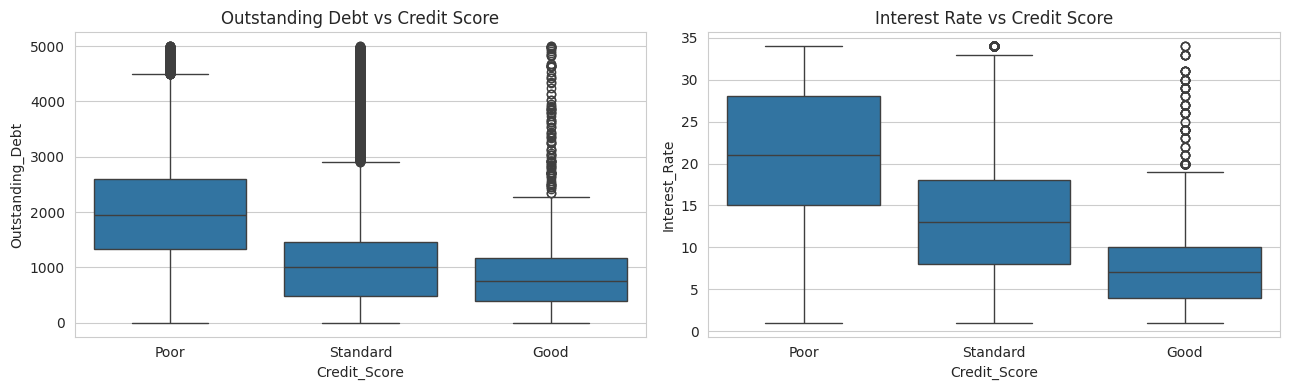

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
sns.boxplot(data=data, x="Credit_Score", y="Outstanding_Debt",
            order=["Poor","Standard","Good"], ax=axes[0])
axes[0].set_title("Outstanding Debt vs Credit Score")
sns.boxplot(data=data, x="Credit_Score", y="Interest_Rate",
            order=["Poor","Standard","Good"], ax=axes[1])
axes[1].set_title("Interest Rate vs Credit Score")
plt.tight_layout(); plt.show()

Pola yang masuk akal: nasabah `Poor` cenderung punya outstanding debt & interest rate lebih tinggi. Artinya fitur-fitur ini punya daya pisah yang bagus.

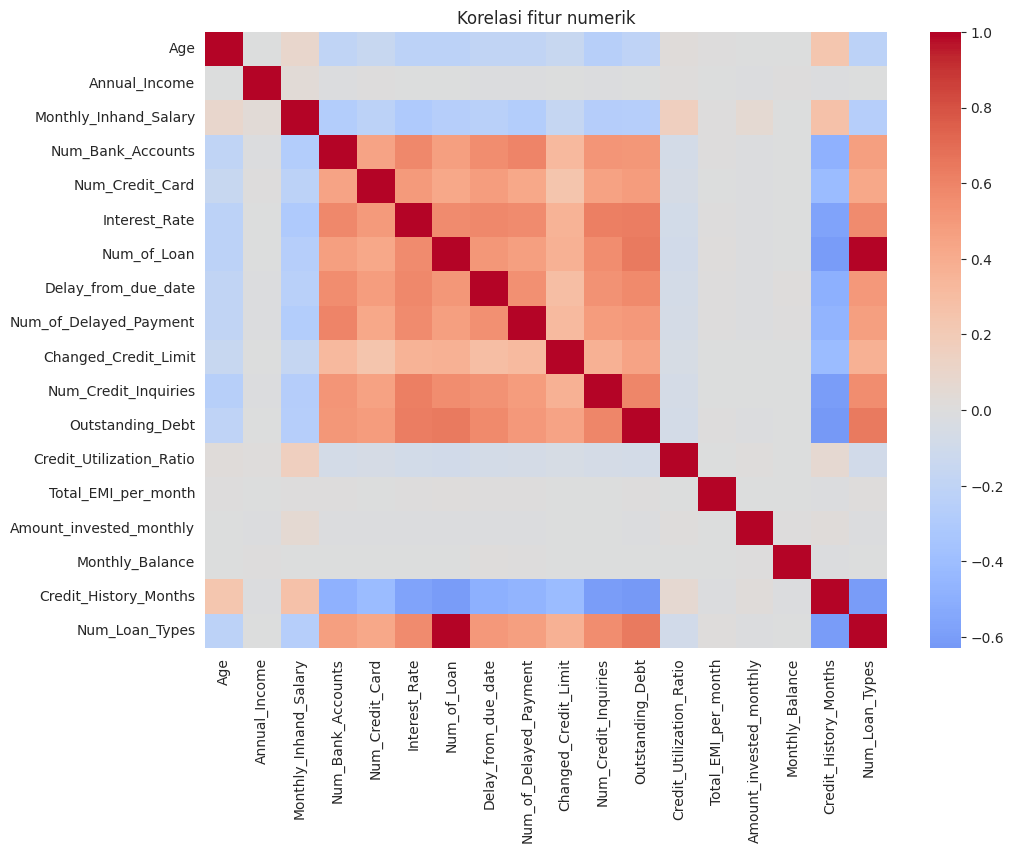

In [10]:
# korelasi antar fitur numerik
num = data.select_dtypes(include=[np.number])
plt.figure(figsize=(11,8))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Korelasi fitur numerik"); plt.show()

## 6. Encoding & Split

- Target di-`LabelEncode` (Good/Poor/Standard → 0/1/2).
- Numerik: impute median + standard scaling.
- Kategorikal: impute modus + one-hot.

Saya bungkus dalam `ColumnTransformer` supaya transformasi konsisten antara train dan test
(dan nanti saat inferensi).

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split

y = LabelEncoder().fit(data["Credit_Score"])
target_names = list(y.classes_)
y_enc = y.transform(data["Credit_Score"])
X = data.drop(columns=["Credit_Score"])

cat_cols = ["Occupation","Credit_Mix","Payment_of_Min_Amount","Payment_Behaviour"]
num_cols = [c for c in X.columns if c not in cat_cols]

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

Xt = pre.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    Xt, y_enc, test_size=0.2, stratify=y_enc, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Kelas:", target_names)

Train: (20000, 45) | Test: (5000, 45)
Kelas: ['Good', 'Poor', 'Standard']


## 7. Eksperimen Model

Saya coba 3 model dengan karakter berbeda:
- **Logistic Regression** — baseline linear.
- **Random Forest** — ensemble bagging, dibatasi kedalamannya biar tidak terlalu besar.
- **XGBoost** — gradient boosting, biasanya kuat di data tabular.

Karena kelas imbalance, perbandingan utama pakai **F1-macro**.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=16,
                        min_samples_leaf=8, class_weight="balanced", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1,
                        subsample=0.9, colsample_bytree=0.9, eval_metric="mlogloss",
                        n_jobs=-1, random_state=42),
}

rows = []
fitted = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    fitted[name] = m
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
        "precision_macro": precision_score(y_test, pred, average="macro"),
        "recall_macro": recall_score(y_test, pred, average="macro"),
    })

hasil = pd.DataFrame(rows).set_index("model").sort_values("f1_macro", ascending=False)
hasil.round(4)

,accuracy,f1_macro,precision_macro,recall_macro
model,,,,
XGBoost,0.7386,0.7152,0.7218,0.7093
Random Forest,0.6962,0.6872,0.6770,0.7326
Logistic Regression,0.6484,0.6407,0.6331,0.6869


**XGBoost** keluar sebagai yang terbaik di F1-macro. Selain itu ukuran model XGBoost jauh
lebih kecil dibanding Random Forest tanpa batasan kedalaman — penting karena model ini akan
di-deploy ke web (file pickle harus ringan). Jadi keputusan saya pakai **XGBoost**.

## 8. Evaluasi model terbaik

Model terbaik: XGBoost

              precision    recall  f1-score   support

        Good       0.66      0.62      0.64       874
        Poor       0.74      0.72      0.73      1460
    Standard       0.76      0.79      0.77      2666

    accuracy                           0.74      5000
   macro avg       0.72      0.71      0.72      5000
weighted avg       0.74      0.74      0.74      5000



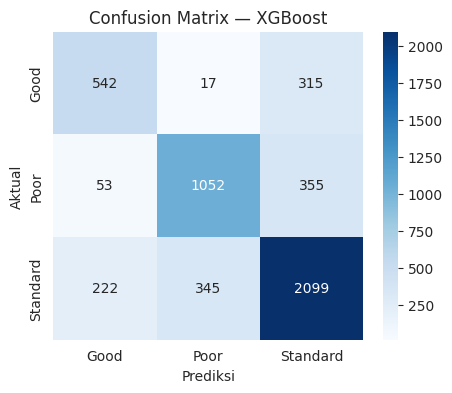

In [13]:
from sklearn.metrics import classification_report, confusion_matrix

best = hasil.index[0]
model = fitted[best]
pred = model.predict(X_test)
print(f"Model terbaik: {best}\n")
print(classification_report(y_test, pred, target_names=target_names))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title(f"Confusion Matrix — {best}")
plt.show()

Kesalahan terbesar ada di antara `Standard` dan dua kelas lain — wajar karena `Standard`
adalah kelas "tengah" yang batasnya kabur. Untuk keperluan institusi, ini sudah cukup baik
sebagai versi awal.

## Catatan akhir

Logic di notebook ini saya pindahkan ke `pipeline.py` dalam bentuk OOP (class
`DataPreprocessor`, `ModelTrainer`, `ModelEvaluator`) + pencatatan **MLflow**, supaya proses
training/retraining ke depannya rapi dan tercatat. Model terbaik + preprocessor disimpan
sebagai pickle, lalu dipakai oleh `inference.py` dan aplikasi `app.py` (Streamlit).